Saving img.jpg to img.jpg


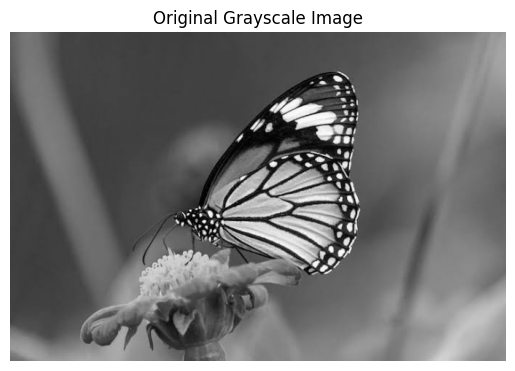

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Upload Image
uploaded = files.upload()

# Read Image
img = cv2.imread(list(uploaded.keys())[0])

# Convert to Grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

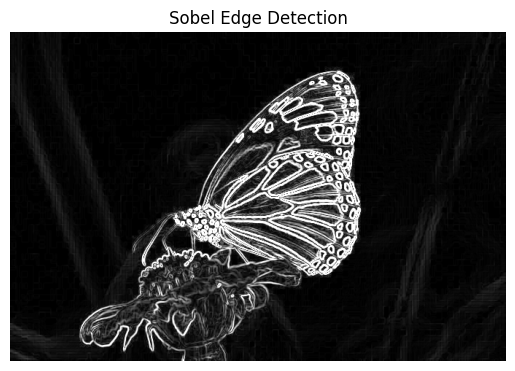

In [2]:
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

plt.imshow(sobel, cmap='gray')
plt.title("Sobel Edge Detection")
plt.axis("off")
plt.show()

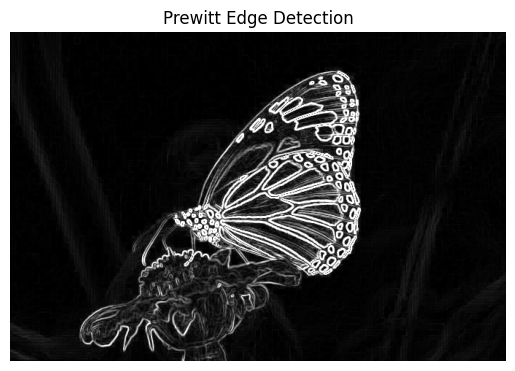

In [3]:
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]])

px = cv2.filter2D(gray, cv2.CV_32F, prewitt_x)
py = cv2.filter2D(gray, cv2.CV_32F, prewitt_y)

prewitt = cv2.magnitude(px, py)
prewitt = cv2.convertScaleAbs(prewitt)

plt.imshow(prewitt, cmap='gray')
plt.title("Prewitt Edge Detection")
plt.axis("off")
plt.show()

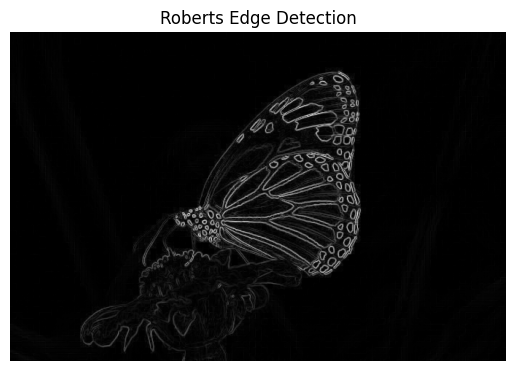

In [4]:
roberts_x = np.array([[1, 0],
                      [0, -1]])

roberts_y = np.array([[0, 1],
                      [-1, 0]])

rx = cv2.filter2D(gray, cv2.CV_32F, roberts_x)
ry = cv2.filter2D(gray, cv2.CV_32F, roberts_y)

roberts = cv2.magnitude(rx, ry)
roberts = cv2.convertScaleAbs(roberts)

plt.imshow(roberts, cmap='gray')
plt.title("Roberts Edge Detection")
plt.axis("off")
plt.show()

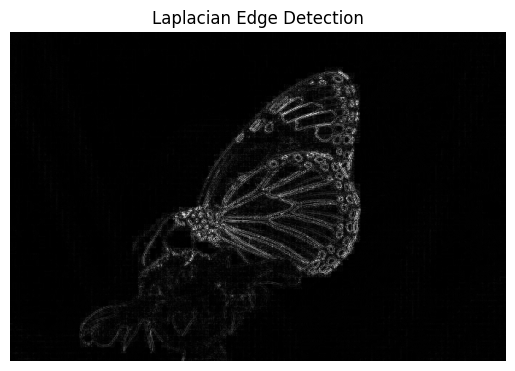

In [5]:
laplacian = cv2.Laplacian(gray, cv2.CV_64F)

laplacian = cv2.convertScaleAbs(laplacian)

plt.imshow(laplacian, cmap='gray')
plt.title("Laplacian Edge Detection")
plt.axis("off")
plt.show()

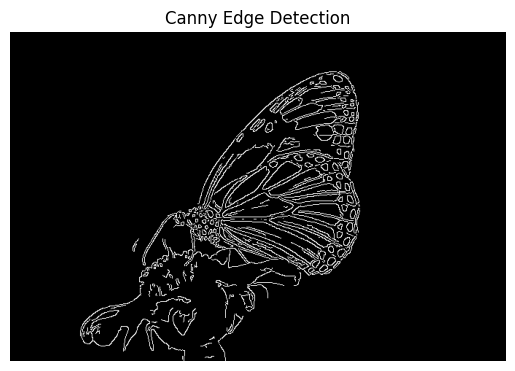

In [6]:
canny = cv2.Canny(gray, 100, 200)

plt.imshow(canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

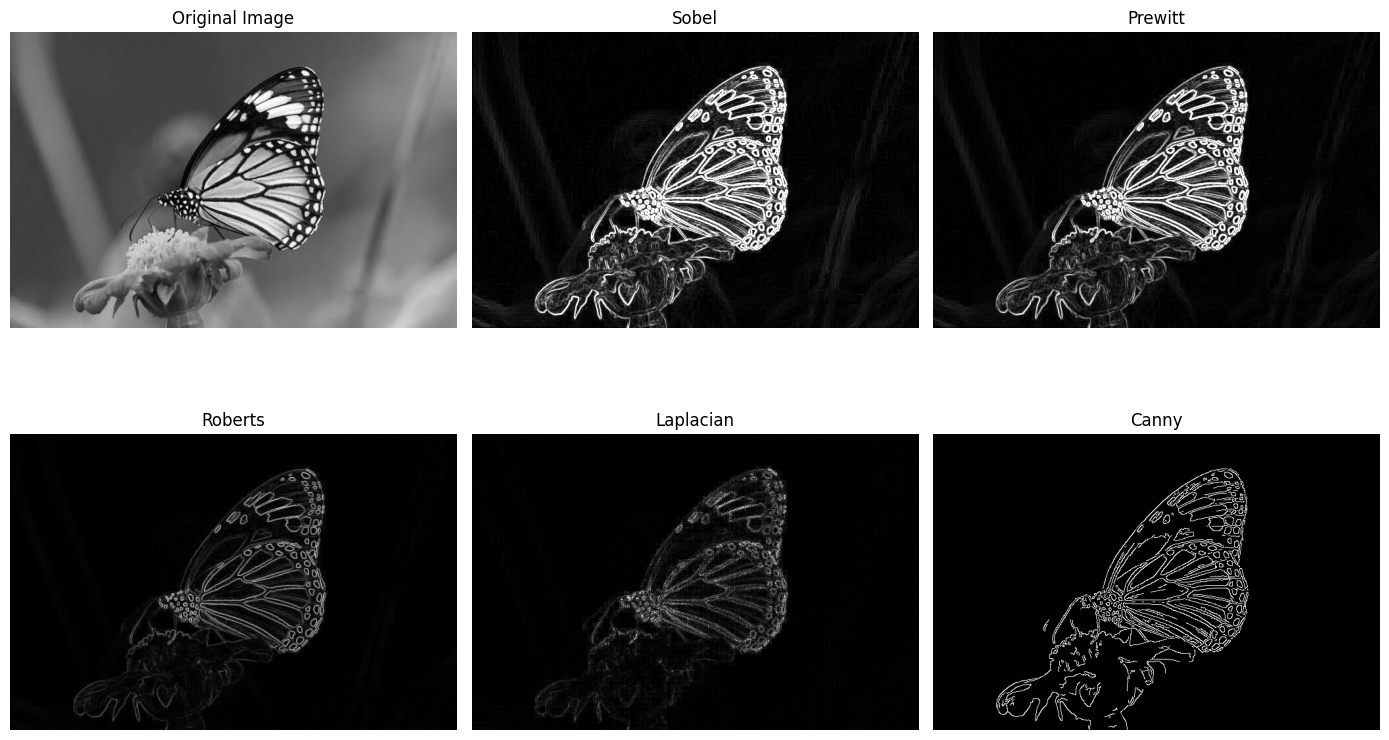

In [7]:
images = [gray, sobel, prewitt, roberts, laplacian, canny]

titles = ["Original Image", "Sobel", "Prewitt",
          "Roberts", "Laplacian", "Canny"]

plt.figure(figsize=(14, 9))

for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()